
# Exploratory Data Analysis

## Objective

Explore the insurance dataset to understand its structure, distributions, and key business patterns before performing detailed claims, risk, policy, settlement, and statistical analyses.

## Scope

- Review dataset dimensions and data types.
- Examine numerical and categorical distributions.
- Identify initial patterns and potential anomalies.
- Prepare observations for deeper analysis in subsequent notebooks.

**Data Source:** MySQL — `insurance_claims_analytics`


In [4]:

# Step 11.2 — Import Libraries for Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

pd.set_option("display.max_columns", None)

print("EDA libraries imported successfully.")


EDA libraries imported successfully.


In [5]:

# Step 11.3 — Connect to MySQL Database

db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("Enter MySQL password: "),
    host="localhost",
    port=3306,
    database="insurance_claims_analytics"
)

engine = create_engine(db_url)

with engine.connect() as connection:
    database = connection.execute(
        text("SELECT DATABASE()")
    ).scalar()

    print("Connected Database:", database)
    print("MySQL connection successful.")


Connected Database: insurance_claims_analytics
MySQL connection successful.


In [6]:

# Step 11.4 — Load MySQL Tables into Pandas

table_names = [
    "customers",
    "policies",
    "claims",
    "payments",
    "risk_assessment",
    "agents",
    "policy_agents",
    "vehicles"
]

data = {}

for table in table_names:
    data[table] = pd.read_sql(
        f"SELECT * FROM {table}",
        con=engine
    )

    print(f"{table}: {data[table].shape[0]:,} rows, "
          f"{data[table].shape[1]} columns")


customers: 10,000 rows, 6 columns
policies: 15,000 rows, 8 columns
claims: 25,000 rows, 7 columns
payments: 15,541 rows, 5 columns
risk_assessment: 10,000 rows, 4 columns
agents: 250 rows, 4 columns
policy_agents: 15,000 rows, 2 columns
vehicles: 6,000 rows, 5 columns


In [7]:

# Step 11.5 — Examine Dataset Structure and Data Types

for table_name, df in data.items():
    print(f"\n{'=' * 60}")
    print(f"TABLE: {table_name.upper()}")
    print(f"{'=' * 60}")

    df.info()



TABLE: CUSTOMERS
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer_ID    10000 non-null  str    
 1   Age            10000 non-null  int64  
 2   Gender         10000 non-null  str    
 3   Region         10000 non-null  str    
 4   Join_Date      10000 non-null  object 
 5   Annual_Income  10000 non-null  float64
dtypes: float64(1), int64(1), object(1), str(3)
memory usage: 468.9+ KB

TABLE: POLICIES
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Policy_ID        15000 non-null  str    
 1   Customer_ID      15000 non-null  str    
 2   Policy_Type      15000 non-null  str    
 3   Start_Date       15000 non-null  object 
 4   End_Date         15000 non-null  object 
 5   Annual_Premium   1500

In [8]:

# Step 11.6 — Identify Date Columns and Data Types

date_columns = []

for table_name, df in data.items():
    for column in df.columns:
        if "date" in column.lower():
            date_columns.append({
                "Table": table_name,
                "Column": column,
                "Current_Dtype": str(df[column].dtype),
                "Non_Null_Count": df[column].notna().sum()
            })

date_summary = pd.DataFrame(date_columns)

display(date_summary)


,Table,Column,Current_Dtype,Non_Null_Count
0,customers,Join_Date,object,10000
1,policies,Start_Date,object,15000
2,policies,End_Date,object,15000
3,claims,Claim_Date,object,25000
4,payments,Payment_Date,object,15541
5,risk_assessment,Assessment_Date,object,10000


In [9]:

# Step 11.7 — Convert Date Columns to Datetime

for table_name, df in data.items():
    for column in df.columns:
        if "date" in column.lower():
            df[column] = pd.to_datetime(
                df[column],
                errors="coerce"
            )

# Verify conversion and check invalid dates
date_validation = []

for table_name, df in data.items():
    for column in df.columns:
        if "date" in column.lower():
            date_validation.append({
                "Table": table_name,
                "Column": column,
                "Data_Type": str(df[column].dtype),
                "Invalid_Dates": df[column].isna().sum()
            })

display(pd.DataFrame(date_validation))


,Table,Column,Data_Type,Invalid_Dates
0,customers,Join_Date,datetime64[s],0
1,policies,Start_Date,datetime64[s],0
2,policies,End_Date,datetime64[s],0
3,claims,Claim_Date,datetime64[s],0
4,payments,Payment_Date,datetime64[s],0
5,risk_assessment,Assessment_Date,datetime64[s],0


In [10]:

# Step 11.8 — Numerical Descriptive Statistics

for table_name, df in data.items():

    numeric_df = df.select_dtypes(include="number")

    if numeric_df.empty:
        continue

    # Exclude numeric identifiers from statistical analysis
    numeric_df = numeric_df.loc[
        :,
        ~numeric_df.columns.str.lower().str.endswith("_id")
    ]

    if numeric_df.empty:
        continue

    print(f"\n{'=' * 55}")
    print(f"TABLE: {table_name.upper()}")
    print(f"{'=' * 55}")

    display(
        numeric_df.describe().T.round(2)
    )



TABLE: CUSTOMERS


,count,mean,std,min,25%,50%,75%,max
Age,10000.0,48.77,18.10,18.0,33.00,49.0,64.00,80.0
Annual_Income,10000.0,1342774.00,664645.34,180109.0,770972.75,1334942.5,1914772.75,2499909.0



TABLE: POLICIES


,count,mean,std,min,25%,50%,75%,max
Annual_Premium,15000.0,22166.86,16306.42,1501.82,11486.78,17778.82,27801.88,222852.66
Coverage_Amount,15000.0,742881.12,645568.05,30162.71,329265.54,559166.56,944612.49,7180476.75



TABLE: CLAIMS


,count,mean,std,min,25%,50%,75%,max
Claim_Amount,25000.0,42145.98,41629.95,450.79,16863.71,29979.78,52626.72,961424.75
Fraud_Flag,25000.0,0.04,0.19,0.00,0.00,0.00,0.00,1.00


... (4 outputs left out)


TABLE: AGENTS


,count,mean,std,min,25%,50%,75%,max
Experience_Years,250.0,11.0,5.78,1.0,6.0,11.0,16.0,20.0



TABLE: VEHICLES


,count,mean,std,min,25%,50%,75%,max
Vehicle_Age,6000.0,7.50,4.59,0.0,4.00,7.0,11.00,15.0
Insured_Value,6000.0,1534548.28,837402.55,100669.0,817674.25,1526316.5,2264254.75,2999982.0


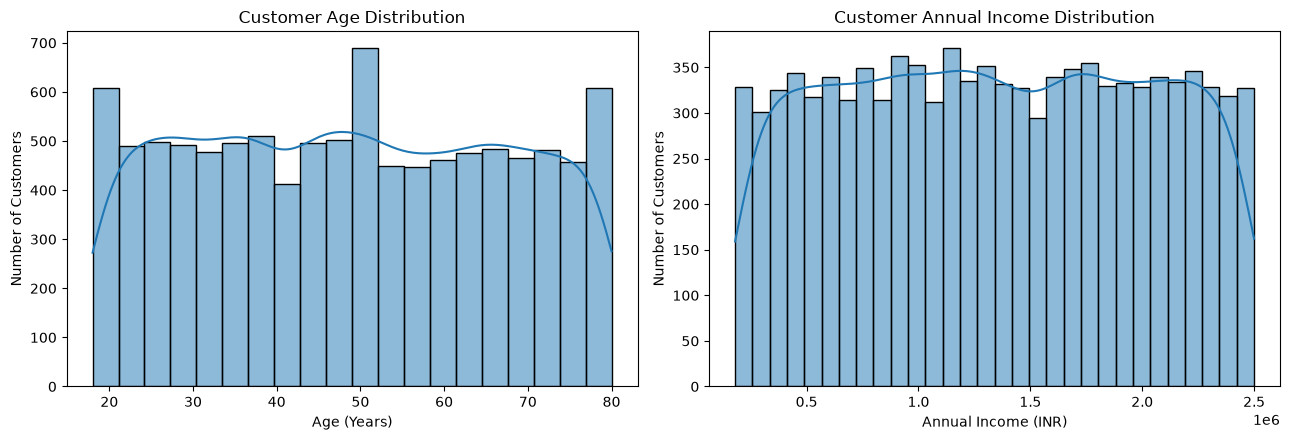

In [11]:

# Step 11.9 — Customer Age and Income Distributions

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(
    data=data["customers"],
    x="Age",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age (Years)")
axes[0].set_ylabel("Number of Customers")

sns.histplot(
    data=data["customers"],
    x="Annual_Income",
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Customer Annual Income Distribution")
axes[1].set_xlabel("Annual Income (INR)")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()



### Key Findings — Customer Demographics

- **Age Distribution:** Customer ages range from 18 to 80 years, with a mean of 48.77 years. The distribution is relatively even across age groups.
- **Income Distribution:** Annual income ranges from approximately ₹1.8 lakh to ₹25 lakh, with a mean of ₹13.43 lakh. Income is broadly distributed without pronounced skewness.
- **Business Interpretation:** The portfolio includes customers across a wide range of ages and income levels. Further segmentation is required to determine whether these demographic differences are associated with policy ownership or claim behavior.


In [12]:

# Step 11.10 — Categorical Distribution Summary

categorical_columns = {
    "customers": ["Gender", "Region"],
    "policies": ["Policy_Type", "Status"],
    "claims": ["Claim_Status"]
}

for table_name, columns in categorical_columns.items():

    for column in columns:

        if column not in data[table_name].columns:
            print(f"Column not found: {table_name}.{column}")
            continue

        print(f"\n{table_name.upper()} — {column}")

        summary = (
            data[table_name][column]
            .value_counts(dropna=False)
            .rename_axis(column)
            .reset_index(name="Count")
        )

        summary["Percentage"] = (
            summary["Count"] / summary["Count"].sum() * 100
        ).round(2)

        display(summary)



CUSTOMERS — Gender


,Gender,Count,Percentage
0,Male,5202,52.02
1,Female,4687,46.87
2,Other,111,1.11



CUSTOMERS — Region


,Region,Count,Percentage
0,West,2029,20.29
1,Central,2018,20.18
2,North,2012,20.12
3,South,1981,19.81
4,East,1960,19.60



POLICIES — Policy_Type


,Policy_Type,Count,Percentage
0,Auto,5953,39.69
1,Health,4560,30.40
2,Home,2691,17.94
3,Life,1796,11.97


Column not found: policies.Status

CLAIMS — Claim_Status


,Claim_Status,Count,Percentage
0,Settled,10569,42.28
1,Approved,6100,24.40
2,Rejected,4256,17.02
3,Pending,4075,16.30


In [13]:

# Check actual column names in the policies table

print(data["policies"].columns.tolist())


['Policy_ID', 'Customer_ID', 'Policy_Type', 'Start_Date', 'End_Date', 'Annual_Premium', 'Coverage_Amount', 'Policy_Status']


In [14]:

# Step 11.10B — Policy Status Distribution

policy_status_summary = (
    data["policies"]["Policy_Status"]
    .value_counts()
    .rename_axis("Policy_Status")
    .reset_index(name="Count")
)

policy_status_summary["Percentage"] = (
    policy_status_summary["Count"]
    / policy_status_summary["Count"].sum() * 100
).round(2)

display(policy_status_summary)


,Policy_Status,Count,Percentage
0,Active,8292,55.28
1,Expired,5218,34.79
2,Cancelled,1490,9.93



### Key Findings — Categorical Distributions

- **Customer Demographics:** Male customers account for 52.02% of the portfolio, while customer distribution across the five regions is nearly balanced.
- **Insurance Products:** Auto insurance represents the largest share of policies (39.69%), followed by Health insurance (30.40%).
- **Policy Status:** Active policies account for 55.28%, Expired policies for 34.79%, and Cancelled policies for 9.93%.
- **Claim Status:** Settled claims represent 42.28%, followed by Approved (24.40%), Rejected (17.02%), and Pending (16.30%).

**Business Interpretation:** Auto insurance dominates the policy portfolio by count, while the presence of expired and cancelled policies highlights the importance of portfolio retention and lifecycle analysis. Claim status distributions provide an initial view of processing outcomes, which will be examined further in the settlement analytics notebook.


In [15]:

# Step 11.11 — Missing Value Summary

missing_summary = pd.DataFrame([
    {
        "Table": table_name,
        "Total_Rows": len(df),
        "Missing_Values": int(df.isna().sum().sum()),
        "Missing_Percentage": round(
            df.isna().sum().sum() / df.size * 100, 2
        )
    }
    for table_name, df in data.items()
])

display(missing_summary)


,Table,Total_Rows,Missing_Values,Missing_Percentage
0,customers,10000,0,0.0
1,policies,15000,0,0.0
2,claims,25000,0,0.0
3,payments,15541,0,0.0
4,risk_assessment,10000,0,0.0
5,agents,250,0,0.0
6,policy_agents,15000,0,0.0
7,vehicles,6000,0,0.0


In [16]:

# Step 11.12 — Date Range Summary

date_range_summary = []

for table_name, df in data.items():
    for column in df.select_dtypes(include="datetime").columns:
        date_range_summary.append({
            "Table": table_name,
            "Date_Column": column,
            "Earliest_Date": df[column].min().date(),
            "Latest_Date": df[column].max().date(),
            "Total_Records": len(df)
        })

display(pd.DataFrame(date_range_summary))


,Table,Date_Column,Earliest_Date,Latest_Date,Total_Records
0,customers,Join_Date,2016-01-01,2024-12-30,10000
1,policies,Start_Date,2020-01-01,2025-12-30,15000
2,policies,End_Date,2020-12-31,2028-12-29,15000
3,claims,Claim_Date,2020-01-05,2026-09-30,25000
4,payments,Payment_Date,2020-02-13,2026-12-24,15541
5,risk_assessment,Assessment_Date,2025-01-01,2026-09-29,10000



### Temporal Coverage and Reporting Considerations

- Customer acquisition records cover 2016–2024.
- Policy inception dates cover 2020–2025, while policy end dates extend through 2028.
- Claims cover January 2020 through September 2026.
- Payment records extend through December 2026.
- Risk assessments cover January 2025 through September 2026.

**Reporting Consideration:** September 30, 2026 will be used as the primary claims reporting cutoff. Payment records after this date should be handled separately in settlement analysis to avoid mixing reporting periods.

**Limitation:** Policy status and policy end dates require careful interpretation because the dataset contains previously identified status-date inconsistencies.


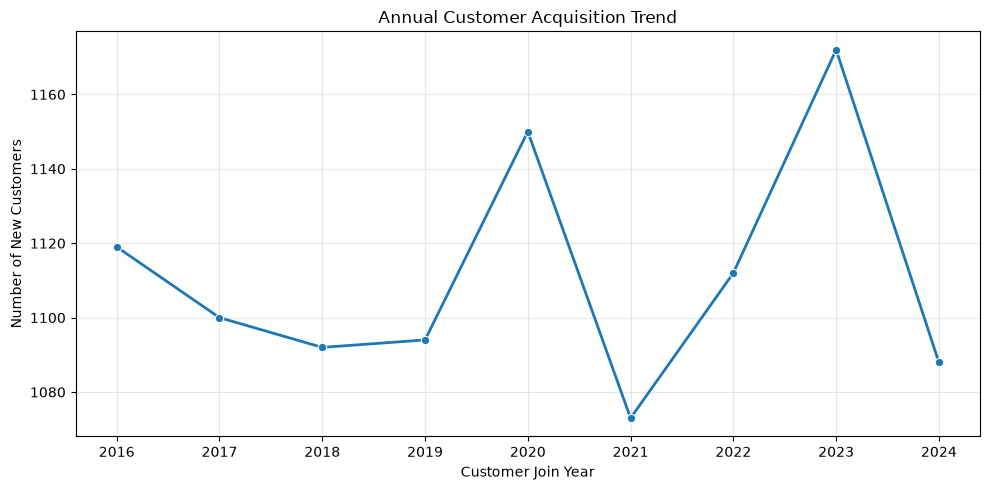

,Join_Year,New_Customers
0,2016,1119
1,2017,1100
2,2018,1092
3,2019,1094
4,2020,1150
5,2021,1073
6,2022,1112
7,2023,1172
8,2024,1088


In [17]:

# Step 11.13 — Annual Customer Acquisition Trend

customer_acquisition = (
    data["customers"]
    .assign(Join_Year=lambda df: df["Join_Date"].dt.year)
    .groupby("Join_Year")
    .size()
    .reset_index(name="New_Customers")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=customer_acquisition,
    x="Join_Year",
    y="New_Customers",
    marker="o",
    linewidth=2
)

plt.title("Annual Customer Acquisition Trend")
plt.xlabel("Customer Join Year")
plt.ylabel("Number of New Customers")
plt.xticks(customer_acquisition["Join_Year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(customer_acquisition)



### Key Findings — Customer Acquisition Trends

- Annual customer acquisition remained relatively stable between 2016 and 2024, ranging from 1,073 to 1,172 customers.
- The highest acquisition occurred in 2023 (1,172 customers), while the lowest occurred in 2021 (1,073 customers).
- New customer acquisition declined by **7.17% in 2024** compared with 2023.

**Year-over-Year Growth Formula:**

$$
\text{YoY Growth (\%)} =
\frac{\text{Current Year Customers} - \text{Previous Year Customers}}
{\text{Previous Year Customers}} \times 100
$$

**Business Interpretation:** Customer acquisition remained broadly stable across the observed period, although the decline in 2024 warrants further investigation. Acquisition counts alone do not establish the reason for the decline.


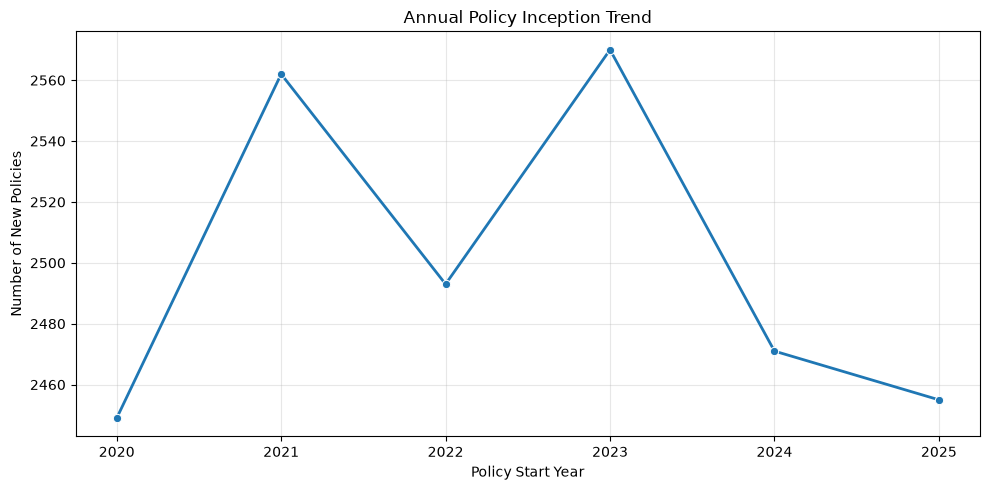

,Start_Year,New_Policies
0,2020,2449
1,2021,2562
2,2022,2493
3,2023,2570
4,2024,2471
5,2025,2455


In [18]:

# Step 11.14 — Annual Policy Inception Trend

policy_inception = (
    data["policies"]
    .assign(Start_Year=lambda df: df["Start_Date"].dt.year)
    .groupby("Start_Year")
    .size()
    .reset_index(name="New_Policies")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=policy_inception,
    x="Start_Year",
    y="New_Policies",
    marker="o",
    linewidth=2
)

plt.title("Annual Policy Inception Trend")
plt.xlabel("Policy Start Year")
plt.ylabel("Number of New Policies")
plt.xticks(policy_inception["Start_Year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(policy_inception)



### Key Findings — Policy Inception Trends

- Annual new policy counts remained relatively stable between 2020 and 2025, ranging from 2,449 to 2,570 policies.
- The highest number of policies started in 2023 (2,570), while the lowest occurred in 2020 (2,449).
- New policy inception declined from 2,471 in 2024 to 2,455 in 2025, representing a **0.65% year-over-year decrease**.

**Business Interpretation:** Policy inception volumes remained broadly consistent, with a modest decline during 2024–2025. Further analysis is required to determine whether this reflects changes in customer demand, product mix, or other factors.


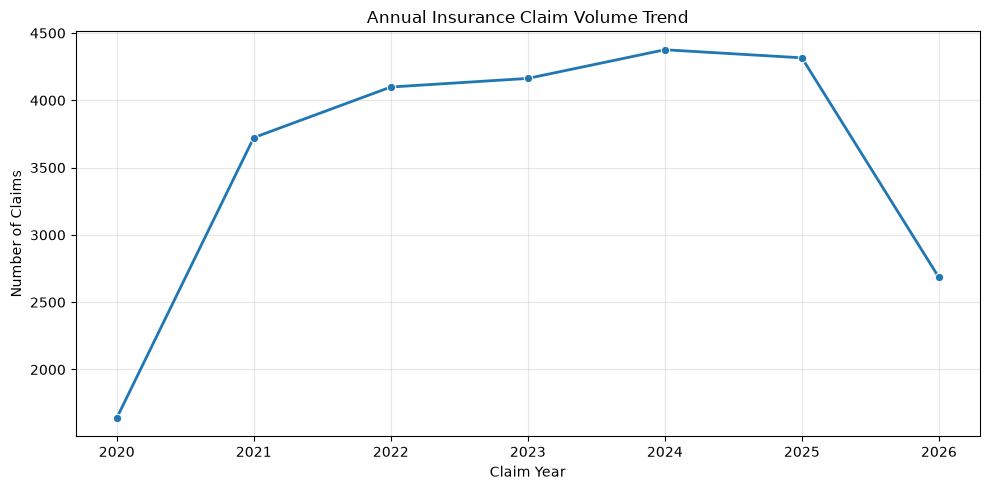

,Claim_Year,Total_Claims
0,2020,1639
1,2021,3723
2,2022,4099
3,2023,4163
4,2024,4376
5,2025,4316
6,2026,2684


In [19]:

# Step 11.15 — Annual Claim Volume Trend

annual_claims = (
    data["claims"]
    .assign(Claim_Year=lambda df: df["Claim_Date"].dt.year)
    .groupby("Claim_Year")
    .size()
    .reset_index(name="Total_Claims")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=annual_claims,
    x="Claim_Year",
    y="Total_Claims",
    marker="o",
    linewidth=2
)

plt.title("Annual Insurance Claim Volume Trend")
plt.xlabel("Claim Year")
plt.ylabel("Number of Claims")
plt.xticks(annual_claims["Claim_Year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(annual_claims)



### Key Findings — Annual Claim Volume

- Claim volume increased from 3,723 in 2021 to a peak of 4,376 in 2024.
- Claims decreased slightly to 4,316 in 2025, representing a **1.37% year-over-year decline**.
- The dataset contains 2,684 claims in 2026 through September 30.

**Business Interpretation:** Claim volumes increased during 2021–2024 before stabilizing in 2025. However, claim counts alone do not establish whether the underlying claim frequency or insurance risk increased, as the number of policies exposed to risk may also have changed.

**Reporting Limitation:** The 2026 data represents a partial year and should not be directly compared with complete calendar years.


C:\Users\Admin\AppData\Local\Temp\ipykernel_24308\90319327.py:26: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  monthly_average["Month_Name"] = pd.to_datetime(


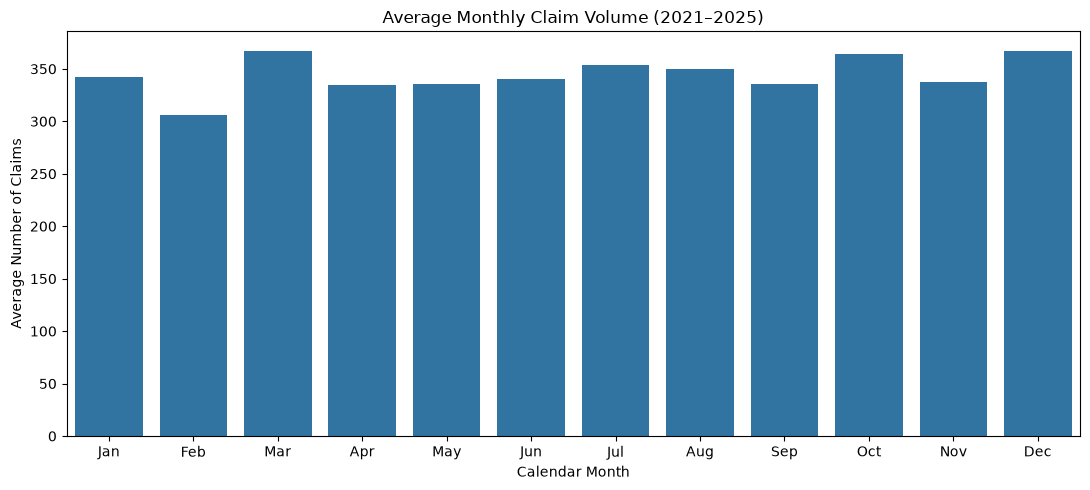

,Month,Average_Claims,Month_Name
0,1,342.6,Jan
1,2,305.8,Feb
2,3,367.2,Mar
3,4,335.0,Apr
4,5,335.6,May
5,6,340.6,Jun
6,7,353.4,Jul
7,8,350.2,Aug
8,9,335.8,Sep
9,10,364.0,Oct


In [20]:

# Step 11.16 — Average Monthly Claim Volume (2021–2025)

claims_df = data["claims"]

complete_year_claims = claims_df[
    claims_df["Claim_Date"].dt.year.between(2021, 2025)
].copy()

monthly_claims = (
    complete_year_claims
    .assign(
        Year=complete_year_claims["Claim_Date"].dt.year,
        Month=complete_year_claims["Claim_Date"].dt.month
    )
    .groupby(["Year", "Month"])
    .size()
    .reset_index(name="Claim_Count")
)

monthly_average = (
    monthly_claims.groupby("Month")["Claim_Count"]
    .mean()
    .reset_index(name="Average_Claims")
)

monthly_average["Month_Name"] = pd.to_datetime(
    monthly_average["Month"], format="%m"
).dt.strftime("%b")

plt.figure(figsize=(11, 5))

sns.barplot(
    data=monthly_average,
    x="Month_Name",
    y="Average_Claims"
)

plt.title("Average Monthly Claim Volume (2021–2025)")
plt.xlabel("Calendar Month")
plt.ylabel("Average Number of Claims")
plt.tight_layout()
plt.show()

display(monthly_average.round(2))



### Key Findings — Monthly Claim Volume

- Average monthly claim volume was calculated using complete calendar years from 2021 to 2025.
- December recorded the highest average (367.4 claims), followed by March (367.2) and October (364.0).
- February recorded the lowest average (305.8 claims).
- Monthly variations were relatively modest, with no clear evidence of strong seasonality from this descriptive analysis.

**Formula — Average Monthly Claim Volume:**

$$
\text{Average Claims for Month }m =
\frac{\sum_{y=2021}^{2025}\text{Claims}_{y,m}}{5}
$$

**Business Interpretation:** Claim volumes are broadly distributed across the year. Differences between months may partly reflect calendar length rather than changes in underlying insurance risk.


In [21]:

# Convert month numbers to abbreviated month names without warnings

import calendar

monthly_average["Month_Name"] = (
    monthly_average["Month"]
    .map(lambda month: calendar.month_abbr[month])
)

display(monthly_average)


,Month,Average_Claims,Month_Name
0,1,342.6,Jan
1,2,305.8,Feb
2,3,367.2,Mar
3,4,335.0,Apr
4,5,335.6,May
5,6,340.6,Jun
6,7,353.4,Jul
7,8,350.2,Aug
8,9,335.8,Sep
9,10,364.0,Oct


In [22]:

# Step 11.17 — Annual Risk Assessment Volume

risk_yearly = (
    data["risk_assessment"]
    .assign(
        Assessment_Year=lambda df: df["Assessment_Date"].dt.year
    )
    .groupby("Assessment_Year")
    .size()
    .reset_index(name="Total_Assessments")
)

risk_yearly["Percentage"] = (
    risk_yearly["Total_Assessments"]
    / risk_yearly["Total_Assessments"].sum() * 100
).round(2)

display(risk_yearly)


,Assessment_Year,Total_Assessments,Percentage
0,2025,5657,56.57
1,2026,4343,43.43


In [23]:

# Step 11.18 — Annual Payment Volume

annual_payments = (
    data["payments"]
    .assign(
        Payment_Year=lambda df: df["Payment_Date"].dt.year
    )
    .groupby("Payment_Year")
    .size()
    .reset_index(name="Total_Payments")
)

display(annual_payments)

print(
    "Total payment records:",
    f"{annual_payments['Total_Payments'].sum():,}"
)


,Payment_Year,Total_Payments
0,2020,789
1,2021,2292
2,2022,2572
3,2023,2567
4,2024,2686
5,2025,2664
6,2026,1971


Total payment records: 15,541


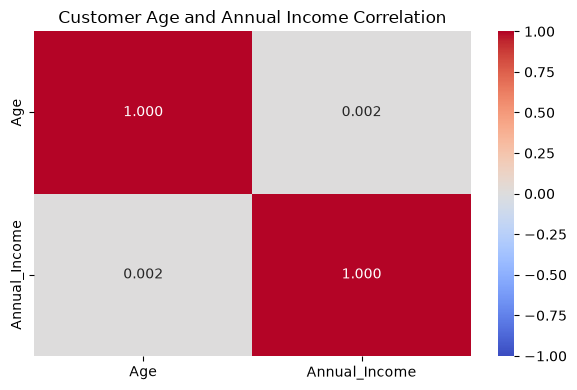

,Age,Annual_Income
Age,1.000000,0.001699
Annual_Income,0.001699,1.000000


In [24]:

# Step 11.19 — Customer Numerical Correlation

customer_corr = data["customers"][
    ["Age", "Annual_Income"]
].corr(method="pearson")

plt.figure(figsize=(6, 4))

sns.heatmap(
    customer_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Customer Age and Annual Income Correlation")
plt.tight_layout()
plt.show()

display(customer_corr)



### Key Findings — Customer Correlation Analysis

- The Pearson correlation coefficient between customer age and annual income is approximately **0.002**.
- This indicates a negligible linear relationship between the two variables.
- Customer age alone does not provide a useful linear indication of annual income in this dataset.

**Business Interpretation:** Age and income should be considered separately when exploring customer characteristics. Additional segmentation or statistical analysis is required before drawing conclusions about customer behavior.

**Limitation:** Pearson correlation measures linear association only and does not establish causation.


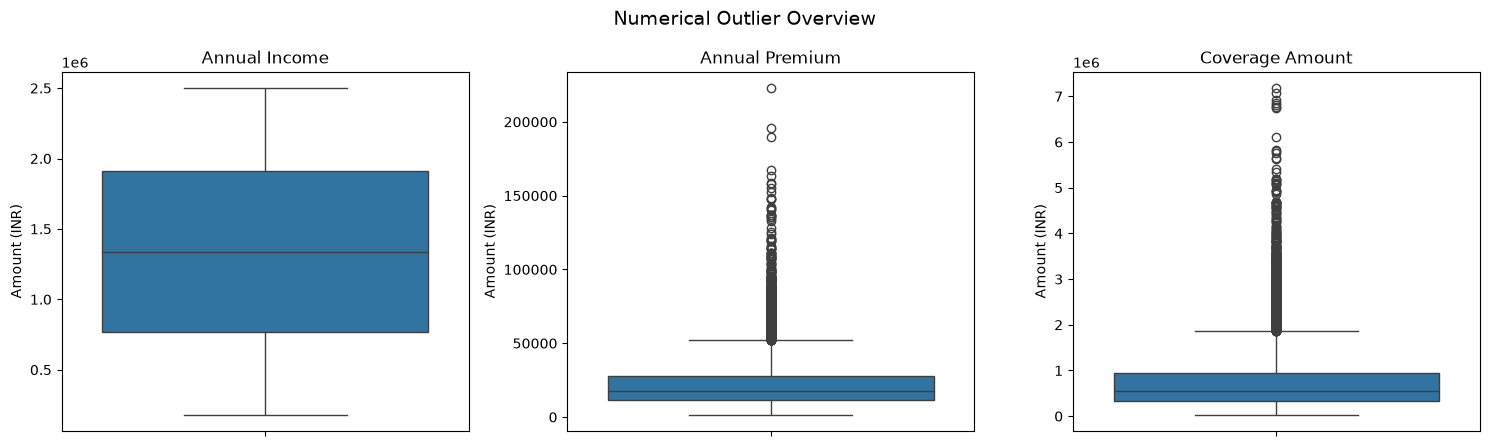

In [25]:

# Step 11.20 — Numerical Outlier Visualization

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

variables = [
    ("customers", "Annual_Income", "Annual Income"),
    ("policies", "Annual_Premium", "Annual Premium"),
    ("policies", "Coverage_Amount", "Coverage Amount")
]

for ax, (table, column, title) in zip(axes, variables):

    sns.boxplot(
        y=data[table][column],
        ax=ax
    )

    ax.set_title(title)
    ax.set_ylabel("Amount (INR)")

plt.suptitle("Numerical Outlier Overview", fontsize=14)
plt.tight_layout()
plt.show()



### Key Findings — Numerical Outlier Analysis

- **Annual Income:** No significant outliers were identified using the boxplot's IQR-based visualization.
- **Annual Premium:** Several high-value observations extend beyond the upper whisker, indicating a right-skewed distribution.
- **Coverage Amount:** Numerous upper-end outliers indicate substantial variation in insurance coverage levels.

**Business Interpretation:** Higher-premium and higher-coverage policies may represent distinct portfolio segments that require further investigation.

**Data Handling:** Outliers are retained because extreme insurance values may be legitimate. No records were removed during exploratory analysis.



## Conclusion — Exploratory Data Analysis

Exploratory Data Analysis was conducted on 96,791 records across eight relational insurance tables.

### Key Findings

1. **Data Completeness:** All eight tables contain complete records with no missing values.
2. **Customer Demographics:** Customers span a broad range of ages and annual incomes, with relatively balanced regional representation.
3. **Insurance Portfolio:** Auto insurance accounts for the largest policy share (39.69%), while 55.28% of policies are classified as Active.
4. **Customer Acquisition:** Annual acquisition remained relatively stable between 2016 and 2024, with a 7.17% decline in 2024.
5. **Policy Inception:** New policy volumes remained broadly consistent during 2020–2025.
6. **Claim Trends:** Claim volume increased during 2021–2024 before declining slightly in 2025. The 2026 data is incomplete.
7. **Monthly Claims:** Claim volumes showed moderate monthly variation without clear evidence of strong seasonality.
8. **Customer Correlation:** Age and annual income exhibited negligible linear correlation (r ≈ 0.002).
9. **Outlier Patterns:** Annual premium and coverage amount contained high-value statistical outliers, which were retained for further analysis.

### Analytical Limitations

- The dataset contains previously identified policy status and date inconsistencies.
- Claim and payment reporting periods are not identical.
- Descriptive relationships do not establish causation.
- Claim frequency and risk comparisons require appropriate exposure measures.

### Next Phase

Proceed to `06_Claims_Severity_Analytics.ipynb` to investigate claim amounts, severity distributions, claim frequency, high-value claims, and claim characteristics.
